<a href="https://colab.research.google.com/github/s4tlaw/KTH_AH2150/blob/main/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Assignment II – Convolutional Neural Networks

Welcome to assignment 2! In this notebook we will help with some parts of the code and the rest is for you to fill in. If you find any errors, or have any feedback, please contact `joelwall@kth.se` or `mats.persson@mi.physics.kth.se`.

In this assignment, we will classify images into three classes. There are five image data sets to choose from, namely:
1. `histopathology` – microscope images of lung tissue (benign, adenocarcinoma, squamous cell carcinoma), RGB,
2. `galaxies` – telescope images of galaxies (spiral, merging, disturbed), RGB,
3. `brain-stroke` – head CT scans (normal, ischemia, bleeding), grayscale,
4. `gravity-wave` – time-frequency spectrograms of LIGO detector glitches (blip, scattered light, whistle), grayscale,
5. `lhc-jets` – simulated particle jets from LHC collisions (gluon, W boson, top quark), grayscale.

All images are 128×128 pixels and each data set is split into a training, validation and test set. Each data set folder contains a `README` with more information about the images and where they come from. Note that `gravity-wave` is smaller than the others (208 training images per class instead of 700).

The goal is to train different classification models in order to achieve high accuracy on the test data set associated to your category of images. First we will perform classification on some hand-crafted features extracted from the image, then we will continue with convolutional neural networks that can automatically learn important features in the images in order to (hopefully!) yield higher classification accuracy.

The exercises are described in the assignment sheet, and the section headers below refer to the exercise numbers there. Code you need to write is marked with `TODO`, and variables you need to define are set to `None`. Answer the questions in your report.

In [ ]:
import os
import random
import numpy as np
from tqdm import tqdm
from PIL import Image

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

SEED = 42
def set_seed(seed=SEED):
    """Seed Python, NumPy and PyTorch so results are reproducible.
    Call it again right before creating/training a model."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # also seeds CUDA

set_seed()

# Setup dataset class
When dealing with more complex datasets, it is recommended to use a custom PyTorch Dataset class to manage your data. This approach allows you to neatly organize how data are loaded, preprocessed, and accessed during training. A dataset class must implement two essential methods:

- `__len__()` — returns the total number of samples in the dataset, and

- `__getitem__(index)` — defines how a single data sample (and its label) is retrieved when the dataset is indexed or iterated over in a training loop.

In [ ]:
class FullImageDataset(Dataset):
    """
    Loads all images from train/val/test directories into memory.
    Directory structure must be:
        root_dir/train/<class_name>/
        root_dir/val/<class_name>/
        root_dir/test/<class_name>/
    Each item is (image, label), where label is an integer class index.
    """

    def __init__(self, root_dir, split='train', transform=None, grayscale=False):
        self.root_dir = os.path.join(root_dir, split)
        self.transform = transform

        # Class names (sorted for consistent label indices)
        self.class_names = sorted([
            d for d in os.listdir(self.root_dir)
            if os.path.isdir(os.path.join(self.root_dir, d))
        ])
        self.num_classes = len(self.class_names)

        self.images, self.labels = [], []
        print(f"Loading {split} data from {self.root_dir} ...")

        for label_idx, class_name in enumerate(self.class_names):
            class_dir = os.path.join(self.root_dir, class_name)
            for fname in tqdm(sorted(os.listdir(class_dir)), desc=f"{class_name}"):
                if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
                    path = os.path.join(class_dir, fname)
                    img = Image.open(path)
                    img = img.convert('L' if grayscale else 'RGB')
                    self.images.append(img)
                    self.labels.append(label_idx)

        self.labels = np.array(self.labels)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = int(self.labels[idx])

        if self.transform:
            img = self.transform(img)

        return img, label

# Load datasets

First we load the training data without any transform and use it to compute the mean and std needed to normalize the images. We then attach the normalizing transform to the training set and load the validation and test sets with the same transform (always using the *training* statistics). The transform is only applied when the CNN reads the data through `__getitem__`; the hand-crafted features below use the raw images.

In [ ]:
data_root = "/content/drive/MyDrive/SH2150/gravity-wave" # TODO: change to your chosen dataset
grayscale = True  # TODO: True for brain-stroke, gravity-wave and lhc-jets; False for histopathology and galaxies (RGB)

def compute_mean_std(pil_images):
    to_tensor = transforms.ToTensor()
    imgs_torch = torch.stack([to_tensor(img) for img in pil_images])
    mean = imgs_torch.mean(dim=[0, 2, 3])
    std  = imgs_torch.std(dim=[0, 2, 3])
    return mean, std

# Just load data without any transform to compute mean and std
train_data = FullImageDataset(data_root, 'train', transform=None, grayscale=grayscale)

mean, std = compute_mean_std(train_data.images)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), std.tolist())
])

print(f"Training data mean: {mean}")
print(f"Training data std:  {std}")

Loading train data from /content/drive/MyDrive/SH2150/gravity-wave/train ...


whistle: 100%|██████████| 208/208 [00:02<00:00, 74.98it/s] 


Training data mean: tensor([0.1396])
Training data std:  tensor([0.0788])


...attach the transform to the training set, and load the validation and test sets with the same transform

In [ ]:
train_data.transform = transform  # no need to reload the training images
val_data  = FullImageDataset(data_root, 'val', transform=transform, grayscale=grayscale)
test_data = FullImageDataset(data_root, 'test', transform=transform, grayscale=grayscale)

X_train, y_train = train_data.images, train_data.labels
X_val, y_val = val_data.images, val_data.labels
X_test, y_test = test_data.images, test_data.labels

print(f"Classes: {train_data.class_names}")
print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")


Loading val data from /content/drive/MyDrive/SH2150/gravity-wave/val ...


whistle: 100%|██████████| 46/46 [00:13<00:00,  3.35it/s]


Loading test data from /content/drive/MyDrive/SH2150/gravity-wave/test ...


whistle: 100%|██████████| 45/45 [00:14<00:00,  3.06it/s]

Classes: ['blip', 'scattered_light', 'whistle']
Train: 624, Val: 138, Test: 135


## Look at the data (exercise 1a)
Before training any model, it is always a good idea to look at the data. Below we plot a few random examples of each class from the training set. What differences between the classes can you see by eye? Which classes do you think will be hardest to tell apart?

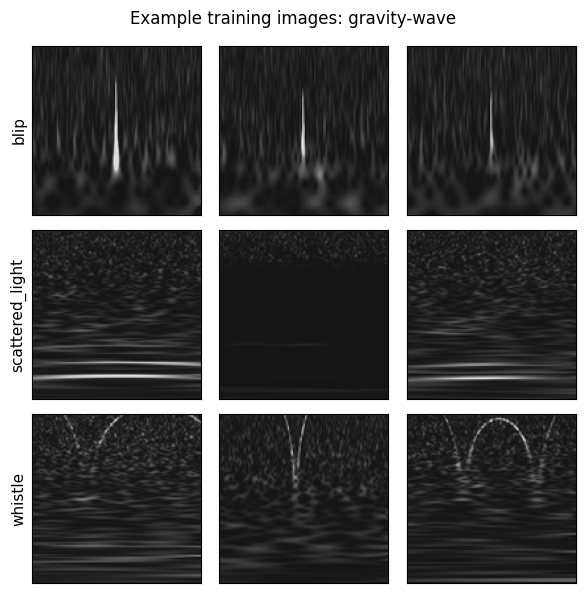

In [ ]:
# Plot a few random example images from each class in the training set
n_examples = 3
class_names = train_data.class_names
rng = np.random.default_rng(0)

fig, axes = plt.subplots(len(class_names), n_examples, figsize=(2 * n_examples, 2 * len(class_names)))
for row, name in enumerate(class_names):
    idx = rng.choice(np.where(train_data.labels == row)[0], n_examples, replace=False)
    for col, i in enumerate(idx):
        img = train_data.images[i]  # PIL image (before normalization)
        ax = axes[row, col]
        ax.imshow(img, cmap='gray' if img.mode == 'L' else None, vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
    axes[row, 0].set_ylabel(name, fontsize=11)

plt.suptitle(f"Example training images: {os.path.basename(data_root)}")
plt.tight_layout(); plt.show()

# Hand-crafted Features (exercise 1a)
Select 3–5 simple, meaningful hand-crafted features and extract them from every image. Explain your choice in the report.

In [ ]:
def extract_features(X):
    """
    Compute simple features from each image.
    Returns an (N, D) array of features.
    """
    feats = []
    for img in tqdm(X):
        arr = np.asarray(img, dtype=np.float32)
        gray = arr if arr.ndim == 2 else arr.mean(axis=-1)  # grayscale images are already (H, W)

        eps = 1e-12
        h, w = gray.shape
        total = gray.sum() + eps
        # Intensity summed along each row and column.
        row_sums = gray.sum(axis=1)
        col_sums = gray.sum(axis=0)

        # 1. Brightness concentrated in a narrow vertical region.
        column_concentration = col_sums.max() / total

        # 2. Brightness concentrated in a narrow horizontal region.
        row_concentration = row_sums.max() / total

        mean_intensity = np.mean(gray)  # If you want, replace with a feature of your choice
        std_intensity = np.std(gray)  # TODO: implement the standard deviation, or replace with another feature of your choice
        # TODO: add your own features until you have 3-5. For example, you can
        # use the mean absolute gradient (edge density) based on np.gradient()
        feats.append([mean_intensity, std_intensity, column_concentration, row_concentration])  # TODO: add your own features to this list
    return np.array(feats)

print("Extracting features...")
X_train_feats = extract_features(X_train)
X_val_feats = extract_features(X_val)
X_test_feats = extract_features(X_test)

# Normalize features (important!)
scaler = StandardScaler()
X_train_feats = scaler.fit_transform(X_train_feats)
X_val_feats = scaler.transform(X_val_feats)
X_test_feats = scaler.transform(X_test_feats)

Extracting features...


100%|██████████| 135/135 [00:00<00:00, 7913.12it/s]


# 1. Unsupervised K-means Clustering (exercise 1b–c)

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)
# TODO: fit the KMeans model to the training features X_train_feats using fit()
kmeans.fit(X_train_feats)

KMeans(n_clusters=3, random_state=42)

In [ ]:
from scipy.stats import mode

# Map each cluster to the most common true label in that cluster
cluster_labels = np.zeros(3, dtype=int)
for i in range(3):
    mask = (kmeans.labels_ == i)
    cluster_labels[i] = mode(y_train[mask], keepdims=False).mode

# Predict on test set
test_clusters = kmeans.predict(X_test_feats)  # TODO: predict cluster indices for the test set
y_pred_kmeans = cluster_labels[test_clusters]

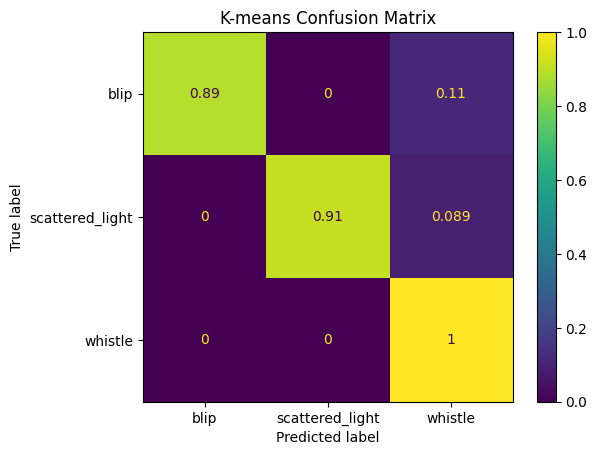

In [ ]:
cm = confusion_matrix(y_test, y_pred_kmeans, normalize='true')
ConfusionMatrixDisplay(cm, display_labels=train_data.class_names).plot()
plt.title("K-means Confusion Matrix")
plt.show()

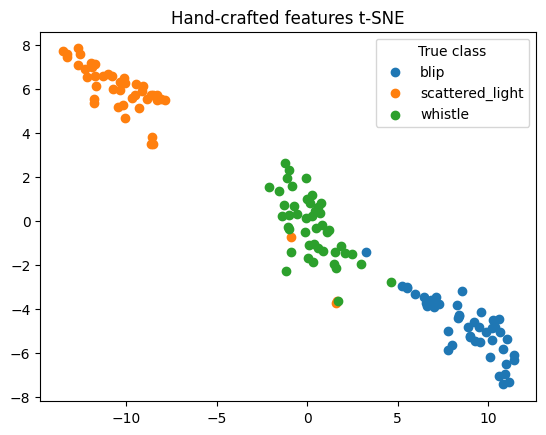

In [ ]:
tsne = TSNE(n_components=2, random_state=42)
X_test_2d = tsne.fit_transform(X_test_feats) # TODO: use fit_transform() to compute a 2D embedding X_test_2d of the test features X_test_feats
plt.figure()
for i, name in enumerate(train_data.class_names):
    plt.scatter(X_test_2d[y_test == i, 0], X_test_2d[y_test == i, 1], label=name)
plt.legend(title='True class'); plt.title("Hand-crafted features t-SNE"); plt.show()

# 2. MLP classifier (exercise 2)

At this point you are ready to code the model in large part by yourself!
Use the below code skeleton which outlines what you need to do. You are welcome to reuse code from the first lab if you want.

In [ ]:
class MLP(nn.Module):
    def __init__(self, in_features: int, hidden_features: list, out_features: int):
        super(MLP, self).__init__()

        layers = []

        # Input → first hidden layer
        layers.append(nn.Linear(in_features, hidden_features[0]))# TODO: append a linear layer (in_features -> hidden_features[0]) to layers
        layers.append(nn.ReLU())# TODO: add a ReLU activation (or try other activation functions)

        # Hidden → hidden
        for i in range(len(hidden_features) - 1):
            layers.append(nn.Linear(hidden_features[i], hidden_features[i + 1]))
            layers.append(nn.ReLU())  # TODO: add linear + activation layers according to hidden_features

        # Last hidden → output layer
        layers.append(nn.Linear(hidden_features[-1], out_features) ) # TODO: add the final linear layer. It should output raw logits (no softmax),
        # since nn.CrossEntropyLoss applies the softmax internally

        # Build the full network
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

In [ ]:
# Convert to torch tensors
X_train_t = torch.tensor(X_train_feats).float()
y_train_t = torch.tensor(y_train).long()
X_val_t   = torch.tensor(X_val_feats).float()
y_val_t   = torch.tensor(y_val).long()

## Train

100%|██████████| 150/150 [00:00<00:00, 242.34it/s]


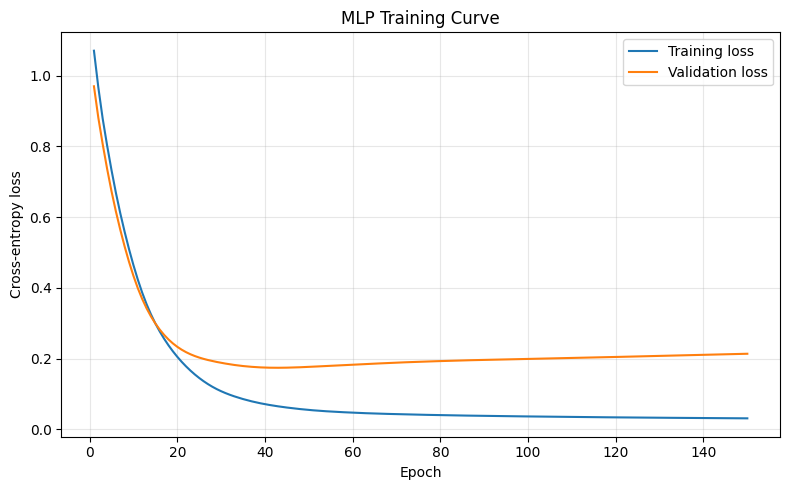

In [ ]:
set_seed()
mlp = MLP(in_features=X_train_feats.shape[1], hidden_features=[512, 32], out_features=3)  # TODO: set the number of output classes
optimizer = torch.optim.Adam(mlp.parameters(), lr=0.001)# TODO: define an Adam optimizer
criterion = nn.CrossEntropyLoss()# TODO: define the loss function (nn.CrossEntropyLoss)

# Training loop
train_losses, val_losses = [], []
num_epochs = 150
for epoch in tqdm(range(num_epochs)):  # TODO: choose a suitable number of epochs
    mlp.train()

    optimizer.zero_grad() # zero the gradients

    out =    mlp(X_train_t) # TODO: forward pass: apply the model to X_train_t
    loss =   criterion(out, y_train_t) # TODO: calculate the loss using criterion(out, y_train_t)

    # TODO: perform a backward pass and update the weights
    loss.backward()
    optimizer.step()

    mlp.eval()
    with torch.no_grad():
        val_out = mlp(X_val_t)# TODO: forward pass on the validation set X_val_t
        val_loss = criterion(val_out, y_val_t)  # TODO: calculate the validation loss

    # TODO: store the training and validation losses in train_losses and val_losses
    train_losses.append(loss.item())
    val_losses.append(val_loss.item())

# TODO: make a plot with two curves: training and validation loss. Don't forget
# the legend. Suggested title "MLP Training Curve"
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Training loss")
plt.plot(epochs, val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("MLP Training Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Evaluate

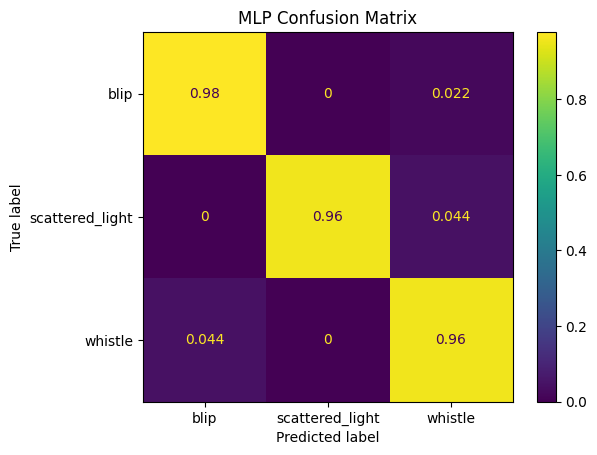

In [ ]:
# Evaluate on test
mlp.eval()
with torch.no_grad():
    y_pred = mlp(torch.tensor(X_test_feats).float()).argmax(1).numpy()

# TODO: plot a confusion matrix similar to the one for K-means above.
# Suggested title "MLP Confusion Matrix"
cm = confusion_matrix(y_test, y_pred, normalize='true')
ConfusionMatrixDisplay(cm, display_labels=train_data.class_names).plot()
plt.title("MLP Confusion Matrix")
plt.show()

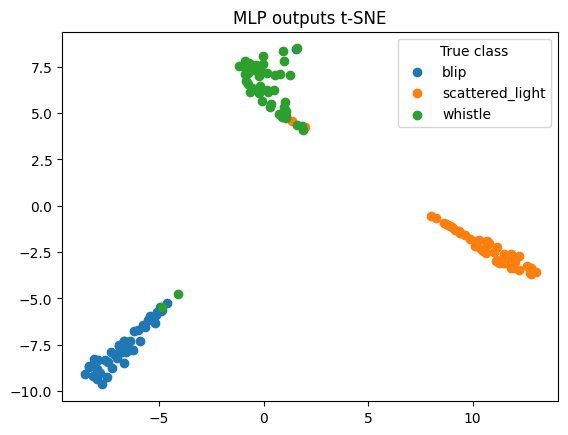

In [ ]:
# Exercise 2c: t-SNE of the output of the final layer of the MLP for every test point
mlp.eval()
with torch.no_grad():
    mlp_out = mlp(torch.tensor(X_test_feats).float()).cpu().numpy()# TODO: apply the MLP to the test features X_test_feats (as a float tensor) and convert the output to numpy

tsne = TSNE(n_components=2, random_state=42)
mlp_out_2d = tsne.fit_transform(mlp_out) # TODO: use fit_transform() to compute a 2D embedding of mlp_out

plt.figure()
for i, name in enumerate(train_data.class_names):
    plt.scatter(mlp_out_2d[y_test == i, 0], mlp_out_2d[y_test == i, 1], label=name)
plt.legend(title='True class'); plt.title("MLP outputs t-SNE"); plt.show()

# 3. CNN (exercise 3)
Exercise 3(a) is a pen-and-paper question, answer it in your report.

In [ ]:
class CNN(nn.Module):
    def __init__(self, in_channels):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 4, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            # TODO: add three more blocks (Conv2d + ReLU + MaxPool2d) according to the CNN
            # architecture in Fig. 1, with 3x3 filters. The last block should have 32 output channels.
            nn.Conv2d(4, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * 8 * 8, 64), nn.ReLU(), nn.Linear(64, 3)
            # TODO: add Linear + ReLU + Linear according to Fig. 1. The last layer should output
            # raw logits (no softmax), since nn.CrossEntropyLoss applies the softmax internally
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
in_channels = train_data[0][0].shape[0]  # 1 for grayscale, 3 for RGB (image tensors are [C, H, W])

set_seed()
cnn = CNN(in_channels = in_channels)
optimizer =  torch.optim.Adam(cnn.parameters(), lr=0.001) # TODO: define an Adam optimizer
criterion =  nn.CrossEntropyLoss() # TODO: define the loss function (nn.CrossEntropyLoss)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))  # reproducible shuffling
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)

train_loss_curve, val_loss_curve = [], []
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn.to(device) # this moves the model to GPU if available

CNN(
  (features): Sequential(
    (0): Conv2d(1, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(4, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=3, bias=True)
  )
)

## Train (exercise 3b)

 10%|█         | 1/10 [00:02<00:26,  2.89s/it]

Epoch 1: Train Loss = 0.4729, Val Loss = 0.0431


 20%|██        | 2/10 [00:06<00:26,  3.32s/it]

Epoch 2: Train Loss = 0.0592, Val Loss = 0.1138


 30%|███       | 3/10 [00:09<00:21,  3.01s/it]

Epoch 3: Train Loss = 0.0533, Val Loss = 0.0583


... (10 outputs left out)

 90%|█████████ | 9/10 [00:25<00:02,  2.77s/it]

Epoch 9: Train Loss = 0.0146, Val Loss = 0.0027


100%|██████████| 10/10 [00:28<00:00,  2.80s/it]

Epoch 10: Train Loss = 0.0132, Val Loss = 0.0015


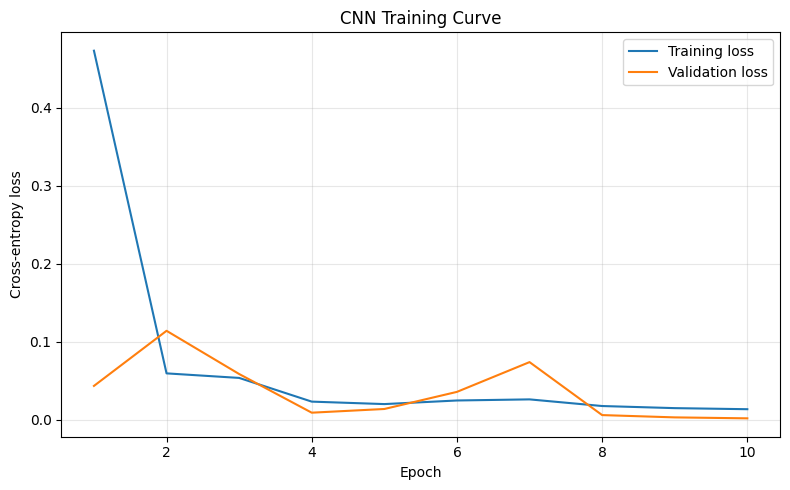

'\noptimizer.zero_grad()          # Clear previous gradients\nout = cnn(imgs)                # Predict class logits\nloss = criterion(out, labels)  # Calculate loss\nloss.backward()                # Compute gradients\noptimizer.step()               # Update weights\n'

In [ ]:
num_epochs = 10
for epoch in tqdm(range(num_epochs)):  # TODO: choose a suitable number of epochs
    cnn.train()
    total_loss = 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        # TODO: zero the gradients, compute the forward pass, calculate the loss `loss`,
        # perform a backward pass and update the weights

        optimizer.zero_grad()

        out = cnn(imgs)
        loss = criterion(out, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
    train_loss_curve.append(total_loss / len(train_loader))

    cnn.eval()
    val_loss = 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            # TODO: calculate the validation loss of this batch and add it to val_loss
            val_out = cnn(imgs)
            val_loss += criterion(val_out, labels).item()

    val_loss_curve.append(val_loss / len(val_loader))

    tqdm.write(f"Epoch {epoch + 1}: Train Loss = {train_loss_curve[-1]:.4f}, Val Loss = {val_loss_curve[-1]:.4f}")

# TODO: make a plot with two curves: training and validation loss, similar to
# before. Suggested title "CNN Training Curve"
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss_curve, label="Training loss")
plt.plot(epochs, val_loss_curve, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("CNN Training Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# '''
# optimizer.zero_grad()          # Clear previous gradients
# out = cnn(imgs)                # Predict class logits
# loss = criterion(out, labels)  # Calculate loss
# loss.backward()                # Compute gradients
# optimizer.step()               # Update weights
# '''

## Evaluate (exercise 3c)

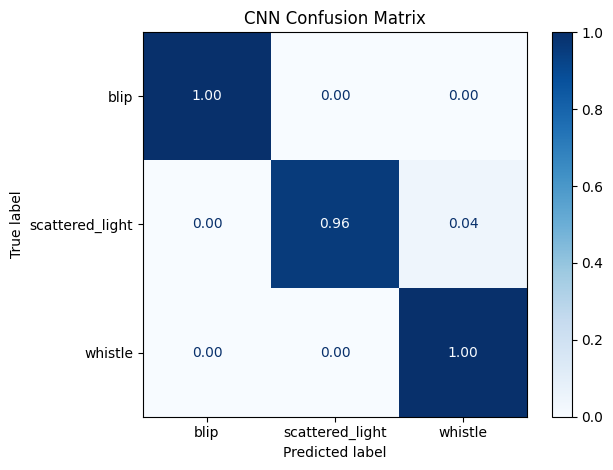

In [ ]:
# Evaluate CNN
cnn.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for imgs, labels in DataLoader(test_data, batch_size=32):
        imgs = imgs.to(device)
        outputs = cnn(imgs)
        y_true.extend(labels.numpy())
        y_pred.extend(outputs.argmax(1).cpu().numpy())

# TODO: plot a confusion matrix similar to before.
# Suggested title "CNN Confusion Matrix"

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    normalize="true"
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_data.class_names
).plot(cmap="Blues", values_format=".2f")

plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()

## Learned features (exercise 3d)
The function below passes images through the first `level` layers of the CNN and returns the flattened activations. Use it to make one t-SNE plot per block, using the validation set.

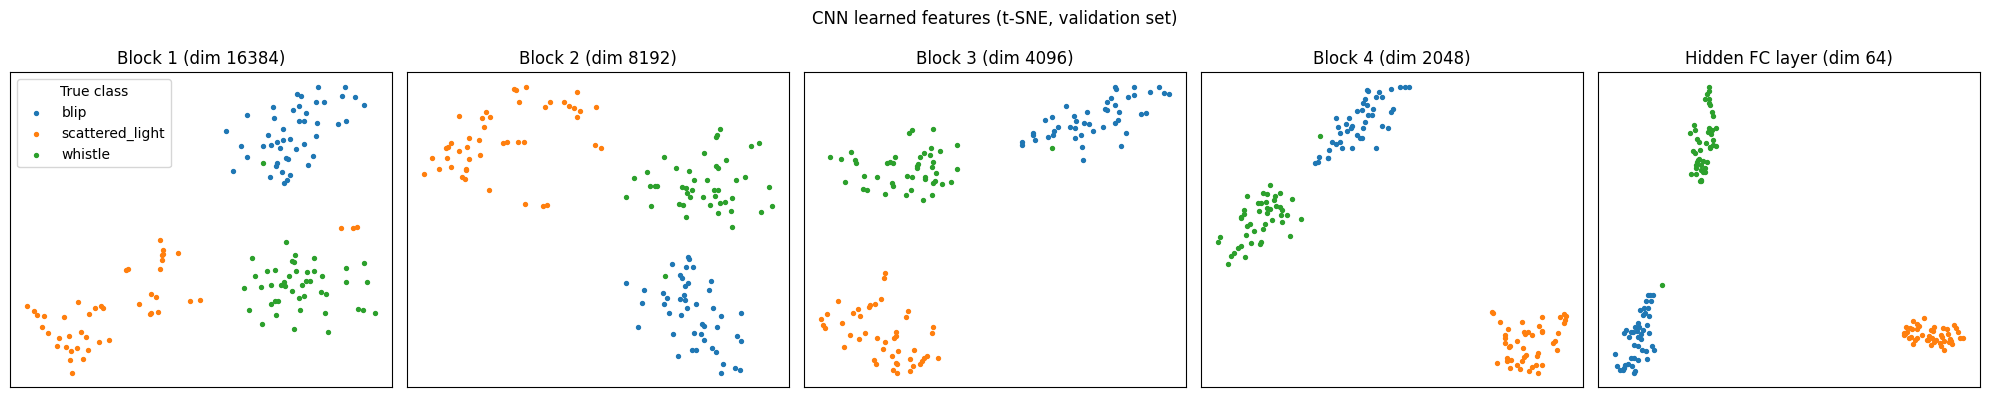

In [ ]:
def get_activations(model, loader, level=1):
    """
    Pass images through the first `level` layers of the CNN and return the
    flattened activations.

    The layers are counted over model.features followed by model.classifier,
    e.g. level=len(model.features) gives the output of the last pooling layer.
    """
    model.eval()
    layers = list(model.features) + list(model.classifier)
    assert 1 <= level <= len(layers), f"level must be between 1 and {len(layers)}"

    feats, labels_all = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            f = imgs.to(device)
            for layer in layers[:level]:
                f = layer(f)  # TODO: pass f through the layer
            feats.append(f.flatten(start_dim=1).cpu())   # shape [N, C*H*W]
            labels_all.append(labels.cpu())

    feats = torch.cat(feats, dim=0).numpy()
    labels_all = torch.cat(labels_all, dim=0).numpy()

    return feats, labels_all


# Exercise 3d: one t-SNE plot per block, using the validation set.
# Output of each convolutional block (after its MaxPool2d): levels 3, 6, 9, 12;
# hidden fully connected layer (after its ReLU): level 15. Check this with print(cnn)
# if you changed the architecture.
levels = {3: 'Block 1', 6: 'Block 2', 9: 'Block 3', 12: 'Block 4', 15: 'Hidden FC layer'}

fig, axes = plt.subplots(1, len(levels), figsize=(4 * len(levels), 4))
for ax, (level, block_name) in zip(axes, levels.items()):
    cnn_feats, cnn_labels = get_activations(cnn, val_loader, level=level)  # TODO: use get_activations() to get the activations at this level for the validation set
    cnn_feats_2d = TSNE(    n_components=2,    random_state=42).fit_transform(cnn_feats)  # TODO: compute a 2D embedding of cnn_feats using t-SNE
    for i, name in enumerate(train_data.class_names):
        ax.scatter(cnn_feats_2d[cnn_labels == i, 0], cnn_feats_2d[cnn_labels == i, 1], s=8, label=name)
    ax.set_title(f"{block_name} (dim {cnn_feats.shape[1]})")
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(title='True class')
plt.suptitle("CNN learned features (t-SNE, validation set)")
plt.tight_layout(); plt.show()

# Discussion (exercise 3e)
Compare the feature spaces of the hand-crafted features (K-means), the MLP and the CNN, and answer the remaining questions, including the final question about AI use, in your report.